# Task 3 - Ai Resume Screening System

Sqrock IT Solutions - Data Science Internship - Phase 1

Goal: read resumes, compare them to a job description with NLP, and rank /
shortlist candidates automatically.

Pipeline (per the internship brief):
  1. Data Collection      -> resume dataset (Hugging Face: AzharAli05/Resume-Screening-Dataset)
                            + PDF->text extraction demo (pypdf)
  2. NLP Preprocessing    -> lowercase, strip punctuation, tokenize, stopwords, lemmatize
  3. Feature Extraction   -> TF-IDF  (and Bag-of-Words comparison)
  4. Matching Algorithm   -> cosine similarity + keyword/skill matching
  5. Ranking System       -> rank by score, show top candidates, filter low scores
  6. Output               -> candidate name, match %, ranking list, shortlist

Script version: resume_screening.py

In [1]:
import os
__file__ = os.path.abspath("resume_screening.py")  # run from the task folder; lets the script's relative paths resolve

In [2]:
from __future__ import annotations

import json
import os
import re
import warnings
from collections import Counter

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")

import nltk
nltk.data.path.insert(0, os.path.abspath(os.path.join(os.path.dirname(__file__), "..", "nltk_data")))
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

HERE = os.path.dirname(os.path.abspath(__file__))
DATA = os.path.join(HERE, "..", "data")
ART = os.path.join(HERE, "artifacts")
WEB = os.path.join(HERE, "..", "web", "assets")
os.makedirs(ART, exist_ok=True); os.makedirs(WEB, exist_ok=True)

PALETTE = {"primary": "#2563eb", "accent": "#f59e0b", "danger": "#ef4444",
           "green": "#10b981", "purple": "#8b5cf6", "slate": "#64748b"}
plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.autolayout": True})


def save(fig, name):
    for d in (ART, WEB):
        fig.savefig(os.path.join(d, name), bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"  [chart] {name}")


TARGET_ROLE = "Data Scientist"
SHORTLIST_N = 10
THRESHOLD = 0.30   # match-score cut-off (fraction)

In [3]:
# Show every chart inline as well as saving it to artifacts/
from IPython.display import Image, display
_save_to_disk = save
def save(fig, name):
    _save_to_disk(fig, name)
    display(Image(os.path.join(ART, name)))

## 1. Collect

In [4]:
print("STEP 1 - Data collection")
raw = pd.read_csv(os.path.join(DATA, "resume_dataset.csv"))
print(f"  loaded {len(raw):,} resume records, roles={raw['Role'].nunique()}")

# normalise the role labels and keep the resumes for our target role
raw["role_norm"] = raw["Role"].str.strip().str.lower()
role_df = raw[raw["role_norm"] == TARGET_ROLE.lower()].copy()
role_df = role_df.dropna(subset=["Resume"]).drop_duplicates(subset=["Resume"]).reset_index(drop=True)
print(f"  '{TARGET_ROLE}' resumes: {len(role_df)}")

# candidate name is embedded in the resume text:  "... resume for Jason Jones:"
def extract_name(text: str, idx: int) -> str:
    m = re.search(r"resume for ([A-Z][a-zA-Z]+(?: [A-Z][a-zA-Z]+){0,2})", text)
    if m:
        return m.group(1).strip()
    m = re.search(r"^\s*([A-Z][a-zA-Z]+(?: [A-Z][a-zA-Z]+){1,2})\s*$", text, re.M)
    if m:
        return m.group(1).strip()
    return f"Candidate #{idx+1}"

role_df["name"] = [extract_name(t, i) for i, t in enumerate(role_df["Resume"])]
# ground-truth label shipped with the dataset (used for a bonus validation)
role_df["label"] = role_df["Decision"].str.lower().map({"select": 1, "reject": 0})

# --- PDF -> text demonstration (brief step 1: "Convert PDFs into text format") ---
pdf_dir = os.path.join(DATA, "sample_resume_pdfs")
os.makedirs(pdf_dir, exist_ok=True)
try:
    import pymupdf
    from pypdf import PdfReader
    for i, txt in enumerate(role_df["Resume"].head(3)):
        doc = pymupdf.open()
        page = doc.new_page()
        page.insert_textbox(pymupdf.Rect(40, 40, 555, 800), txt[:2600], fontsize=8)
        p = os.path.join(pdf_dir, f"resume_{i+1}.pdf")
        doc.save(p); doc.close()
    # read them back to prove the pipeline works end-to-end from PDF
    pdf_files = [os.path.join(pdf_dir, f) for f in sorted(os.listdir(pdf_dir)) if f.endswith(".pdf")]
    pdf_texts = [("\n".join(pg.extract_text() or "" for pg in PdfReader(p).pages)) for p in pdf_files]
    n_ok = sum(1 for t in pdf_texts if len(t.strip()) > 50)
    print(f"  PDF round-trip OK: {len(pdf_files)} PDFs written, {n_ok} re-parsed with pypdf "
          f"(avg {np.mean([len(t) for t in pdf_texts]):.0f} chars)")
except Exception as e:  # pragma: no cover
    print("  PDF demo skipped:", str(e)[:90])

STEP 1 - Data collection


  loaded 10,174 resume records, roles=45
  'Data Scientist' resumes: 825
  PDF demo skipped: No module named 'pymupdf'


## 2. Nlp Preprocess

In [5]:
print("STEP 2 - NLP preprocessing")
STOP = set(stopwords.words("english"))
STOP |= {"experience", "work", "team", "years", "year", "company", "role", "job",
         "skills", "skill", "using", "used", "including", "responsible", "strong",
         "ability", "knowledge", "plus", "etc", "well", "also", "new", "across"}
LEM = WordNetLemmatizer()


def clean(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)          # URLs
    text = re.sub(r"\S+@\S+", " ", text)                   # emails
    text = re.sub(r"[^a-z\s]", " ", text)                  # punctuation / digits / symbols
    toks = word_tokenize(text)
    toks = [LEM.lemmatize(t) for t in toks if t not in STOP and len(t) > 2]
    return " ".join(toks)


role_df["clean"] = role_df["Resume"].map(clean)

# Build a realistic job description for the role (combining dataset JDs + a canonical spec)
dataset_jds = role_df["Job_Description"].dropna().astype(str).tolist()
JD = (
    "We are hiring a Data Scientist to build machine learning models and turn data into "
    "business insight. Responsibilities: collect and clean data, perform exploratory data "
    "analysis, engineer features, train and evaluate machine learning models using python, "
    "pandas, numpy, scikit-learn, tensorflow or pytorch, deploy models, build dashboards and "
    "communicate results. Required skills: python, sql, statistics, machine learning, deep "
    "learning, data analysis, data visualization, nlp, big data, aws, docker, git. "
    "Experience with A/B testing, time series, regression and classification. "
) + " ".join(dataset_jds[:40])
jd_clean = clean(JD)
print(f"  job description: {len(JD)} chars -> {len(jd_clean.split())} clean tokens")

STEP 2 - NLP preprocessing


  job description: 5496 chars -> 493 clean tokens


## 3. Feature Extraction

In [6]:
print("STEP 3 - Feature extraction (TF-IDF + Bag-of-Words)")
corpus = role_df["clean"].tolist()
tfidf = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), sublinear_tf=True)
X_res = tfidf.fit_transform(corpus)
x_jd = tfidf.transform([jd_clean])
cos = cosine_similarity(X_res, x_jd).ravel()
print(f"  TF-IDF matrix: {X_res.shape[0]} resumes x {X_res.shape[1]} terms")

bow = CountVectorizer(max_features=3000)
B_res = bow.fit_transform(corpus); b_jd = bow.transform([jd_clean])
cos_bow = cosine_similarity(B_res, b_jd).ravel()

STEP 3 - Feature extraction (TF-IDF + Bag-of-Words)


  TF-IDF matrix: 825 resumes x 3000 terms


## 4. Matching

In [7]:
print("STEP 4 - Matching algorithm (cosine similarity + keyword/skill matching)")
SKILLS = ["python", "sql", "statistics", "machine learning", "deep learning", "nlp",
          "tensorflow", "pytorch", "scikit", "pandas", "numpy", "data analysis",
          "data visualization", "tableau", "power bi", "spark", "hadoop", "aws", "azure",
          "docker", "kubernetes", "git", "excel", "r", "time series", "a b testing",
          "regression", "classification", "clustering", "etl", "airflow"]


# Whole-word / whole-phrase matching. A plain substring test would count "r" in
# every resume, "git" inside "digital", "aws" inside "laws", "etl" inside "netlify".
_SKILL_RE = {
    s: re.compile(r"(?<![a-z0-9])" + r"[\s\-/]*".join(map(re.escape, s.split())) + r"(?![a-z0-9])")
    for s in SKILLS
}
_SKILL_RE["scikit"] = re.compile(r"(?<![a-z0-9])(scikit|sklearn)(?![a-z0-9])")
_SKILL_RE["a b testing"] = re.compile(r"(?<![a-z0-9])a\s*/?\s*b[\s\-]*test(ing)?(?![a-z0-9])")


def skill_hits(text: str) -> list[str]:
    t = str(text).lower()
    return [s for s in SKILLS if _SKILL_RE[s].search(t)]


role_df["skills"] = role_df["Resume"].map(skill_hits)
role_df["skill_count"] = role_df["skills"].map(len)
skill_score = role_df["skill_count"] / len(SKILLS)

# blended match score: 65% semantic (TF-IDF cosine) + 35% keyword/skill coverage
role_df["tfidf_score"] = cos
role_df["bow_score"] = cos_bow
role_df["keyword_score"] = skill_score
role_df["match_score"] = (0.65 * role_df["tfidf_score"] + 0.35 * role_df["keyword_score"])
# scale to a friendly 0-100 percentage (relative to the best match in the pool)
role_df["match_pct"] = (role_df["match_score"] / role_df["match_score"].max() * 100).round(1)

STEP 4 - Matching algorithm (cosine similarity + keyword/skill matching)


## 5. Ranking

STEP 5 - Ranking system
  ranked 825 resumes | shortlisted 10 (top 10, score >= 0.3)


  [chart] t3_top_candidates.png


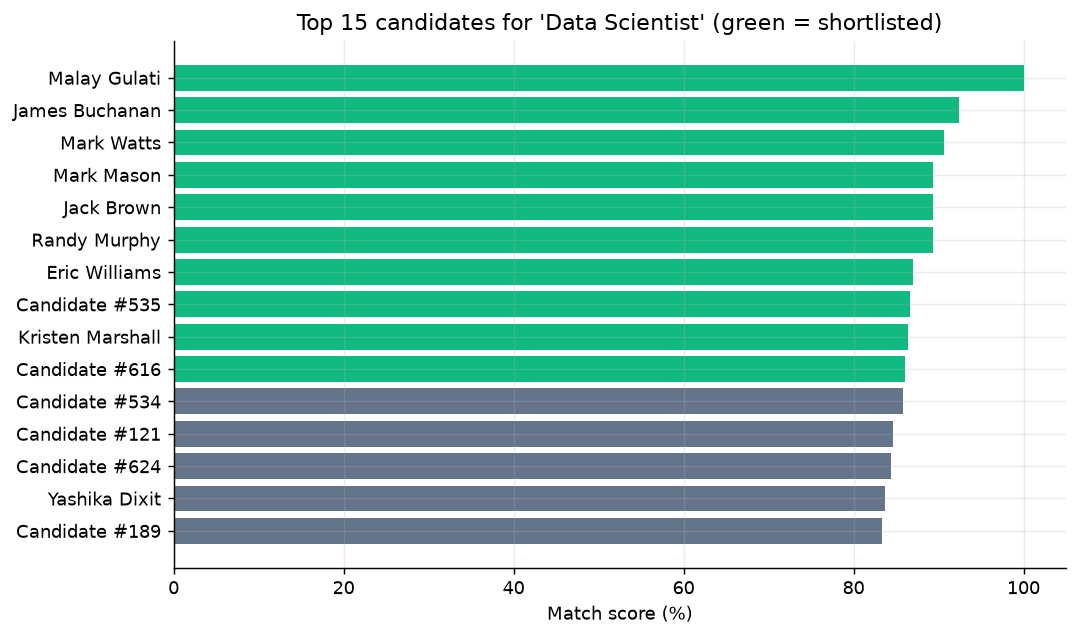

  [chart] t3_score_dist.png


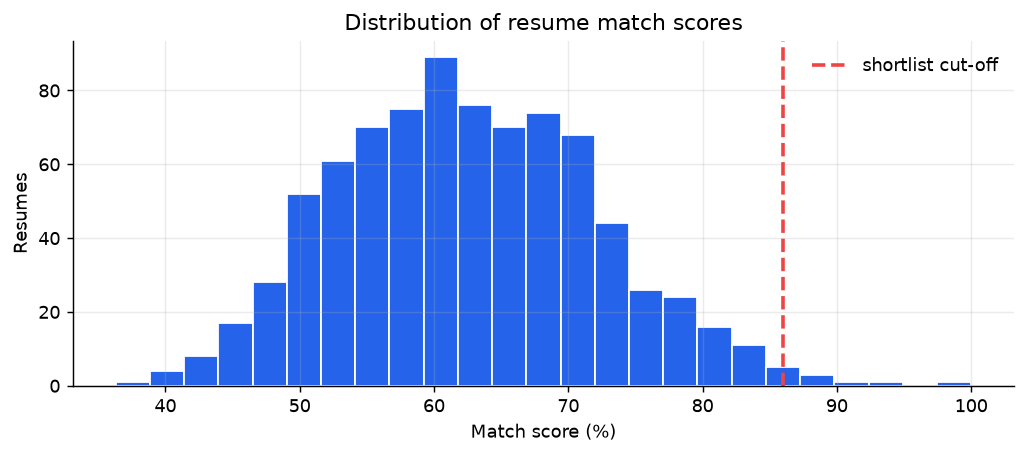

  [chart] t3_skill_coverage.png


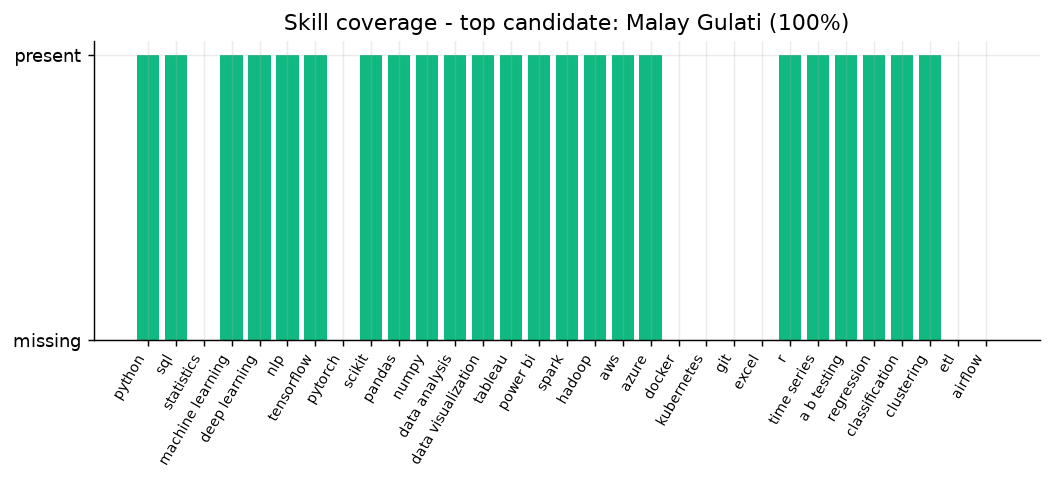

In [8]:
print("STEP 5 - Ranking system")
ranked = role_df.sort_values("match_score", ascending=False).reset_index(drop=True)
ranked["rank"] = ranked.index + 1
ranked["shortlisted"] = np.where(
    (ranked["rank"] <= SHORTLIST_N) & (ranked["match_score"] >= THRESHOLD), "YES", "NO")
shortlist = ranked[ranked["shortlisted"] == "YES"]
print(f"  ranked {len(ranked)} resumes | shortlisted {len(shortlist)} "
      f"(top {SHORTLIST_N}, score >= {THRESHOLD})")

# charts
top = ranked.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.barh(top["name"], top["match_pct"],
        color=[PALETTE["green"] if s == "YES" else PALETTE["slate"] for s in top["shortlisted"]])
ax.set_title(f"Top 15 candidates for '{TARGET_ROLE}' (green = shortlisted)")
ax.set_xlabel("Match score (%)")
save(fig, "t3_top_candidates.png")

fig, ax = plt.subplots(figsize=(8.0, 3.6))
ax.hist(ranked["match_pct"], bins=25, color=PALETTE["primary"], edgecolor="white")
ax.axvline(ranked.loc[ranked["shortlisted"] == "YES", "match_pct"].min(),
           color=PALETTE["danger"], ls="--", lw=2, label="shortlist cut-off")
ax.set_title("Distribution of resume match scores")
ax.set_xlabel("Match score (%)"); ax.set_ylabel("Resumes"); ax.legend(frameon=False)
save(fig, "t3_score_dist.png")

# skill coverage for the top candidate
top1 = ranked.iloc[0]
fig, ax = plt.subplots(figsize=(8.2, 3.8))
present = [s for s in SKILLS if s in top1["skills"]]
cov = pd.Series({s: (1 if s in top1["skills"] else 0) for s in SKILLS})
ax.bar(cov.index, cov.values, color=[PALETTE["green"] if v else "#e5e7eb" for v in cov.values])
ax.set_xticklabels(cov.index, rotation=60, ha="right", fontsize=8)
ax.set_title(f"Skill coverage - top candidate: {top1['name']} ({top1['match_pct']:.0f}%)")
ax.set_yticks([0, 1]); ax.set_yticklabels(["missing", "present"])
save(fig, "t3_skill_coverage.png")

## 6. Output

In [9]:
print("STEP 6 - Output & evaluation")
# bonus: does the shortlist agree with the dataset's own select/reject labels?
# (labels in this dataset are noisy, so this is an indicative signal only)
have_label = ranked[ranked["label"].notna()]
baseline = float(have_label["label"].mean()) if len(have_label) else None
sl_rate = float(have_label.head(SHORTLIST_N)["label"].mean()) if len(have_label) else None
lift = (sl_rate - baseline) if baseline is not None else None
print(f"  shortlist 'select' rate={sl_rate} vs pool baseline={round(baseline,3) if baseline else None} "
      f"(lift={round(lift,3) if lift is not None else None})")

metrics = {
    "task": "AI Resume Screening System",
    "dataset": "Resume Screening Dataset (Hugging Face: AzharAli05/Resume-Screening-Dataset)",
    "target_role": TARGET_ROLE,
    "resumes_screened": int(len(ranked)),
    "vectorizer": "TF-IDF (1-2 grams, 3000 features, sublinear_tf)",
    "matching": "cosine similarity (65%) + skill/keyword coverage (35%)",
    "pdf_to_text_demo": "3 sample resumes rendered to PDF and re-parsed with pypdf",
    "shortlist_size": int(len(shortlist)),
    "shortlist_threshold": THRESHOLD,
    "mean_score": round(float(ranked["match_pct"].mean()), 2),
    "top_candidate": {"name": top1["name"], "score": float(top1["match_pct"]),
                      "skills": top1["skills"]},
    "shortlist_select_rate": None if sl_rate is None else round(sl_rate, 3),
    "pool_baseline_select_rate": None if baseline is None else round(baseline, 3),
    "shortlist_lift_vs_baseline": None if lift is None else round(lift, 3),
}
with open(os.path.join(ART, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
out = ranked[["rank", "name", "match_pct", "tfidf_score", "keyword_score",
              "skill_count", "shortlisted", "label"]].round(4)
out.to_csv(os.path.join(ART, "ranking.csv"), index=False)
shortlist[["rank", "name", "match_pct", "skills", "shortlisted"]].to_csv(
    os.path.join(ART, "shortlist.csv"), index=False)

web_payload = {
    "metrics": metrics,
    "top": {"names": ranked.head(15)["name"].tolist(),
            "scores": ranked.head(15)["match_pct"].tolist(),
            "shortlisted": ranked.head(15)["shortlisted"].tolist()},
    "dist": ranked["match_pct"].tolist(),
    "cutoff": float(ranked.loc[ranked["shortlisted"] == "YES", "match_pct"].min())
              if len(shortlist) else 0.0,
    "skills_all": SKILLS,
    "top1_skills": top1["skills"],
    "ranking": ranked[["rank", "name", "match_pct", "skill_count", "shortlisted"]]
                 .head(40).round(1).to_dict(orient="records"),
    "jd_preview": JD[:420] + "...",
}
with open(os.path.join(WEB, "t3_data.json"), "w") as f:
    json.dump(web_payload, f)

print("\n  TOP 10 SHORTLIST")
print(shortlist[["rank", "name", "match_pct"]].head(10).to_string(index=False))
print("TASK 3 COMPLETE")

STEP 6 - Output & evaluation
  shortlist 'select' rate=0.6 vs pool baseline=0.498 (lift=0.102)

  TOP 10 SHORTLIST
 rank             name  match_pct
    1     Malay Gulati      100.0
    2   James Buchanan       92.4
    3       Mark Watts       90.6
    4       Mark Mason       89.4
    5       Jack Brown       89.4
    6     Randy Murphy       89.3
    7    Eric Williams       87.0
    8   Candidate #535       86.7
    9 Kristen Marshall       86.4
   10   Candidate #616       86.0
TASK 3 COMPLETE
